# Bank Marketing - Machine Learning Project

## 1. Project and Dataset Description

### Objective
Predict whether a bank client will subscribe to
a term deposit using machine learning.

### Dataset
- Name: Bank Marketing
- Original source: https://www.openml.org/d/1461
- Number of instances: 45,211
- Target variable: y
- Task: Binary classification

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.ensemble import IsolationForest

## 2. Data Access

The dataset is hosted in our GitHub repository
to ensure reproducibility: https://github.com/JMazatIMT/Auto-Learning-Project/raw/refs/heads/main/data/bank_marketing.csv

In [12]:
DATA_URL = (
    "https://raw.githubusercontent.com/"
    "JMazatIMT/Auto-Learning-Project/main/data/bank_marketing.csv"
)

df = pd.read_csv(DATA_URL)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (45211, 17)


,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,1
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,1
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,1
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,1
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,1


## 3. Data Exploratory Analysis

### 3.1. Dataset Metadata

The OpenML dataset uses generic feature names (`V1` to `V16`). We rename them according to the original [Bank Marketing dataset documentation](https://archive.ics.uci.edu/dataset/222/bank+marketing) to improve interpretability.

In [13]:
df = df.rename(columns={
    "V1": "age", "V2": "job", "V3": "marital", "V4": "education",
    "V5": "default", "V6": "balance", "V7": "housing", "V8": "loan",
    "V9": "contact", "V10": "day", "V11": "month", "V12": "duration",
    "V13": "campaign", "V14": "pdays", "V15": "previous", "V16": "poutcome"
})

features = df.drop(columns="y")
numerical_features = features.select_dtypes(include="number").columns.tolist()
categorical_features = features.select_dtypes(exclude="number").columns.tolist()
df.info()
print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  int64 
dtypes: int64(8), object(9)
memory usage: 5.9+ MB
Numerical features: ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']
Categoric

The target column `y` is excluded from the input feature lists, even though it is stored as an integer. The dataset contains 16 input features: 7 numerical and 9 categorical.

### 3.2. Test Set Isolation

We reserve 20% of the data for the final evaluation. Stratification preserves the class proportions, and a fixed random state makes the split reproducible. The remaining 80% will be used for exploration, training and cross-validation.

In [14]:
df_train, df_test = train_test_split(
    df, test_size=0.2, random_state=42, stratify=df["y"]
)
df_eda = df_train.copy()
print("Development set:", df_train.shape, "Test set:", df_test.shape)

Development set: (36168, 17) Test set: (9043, 17)


### 3.3. Missing Values and Duplicates

We check both standard missing values (NaN) and the explicit `unknown` category. We also check for identical rows.

In [15]:
display(pd.DataFrame({
    "Missing": df_eda.isna().sum(),
    "Unknown": df_eda.eq("unknown").sum()
}))
print("Duplicated rows:", df_eda.duplicated().sum())

,Missing,Unknown
age,0,0
job,0,234
marital,0,0
education,0,1482
default,0,0
balance,0,0
housing,0,0
loan,0,0
contact,0,10386
day,0,0


Duplicated rows: 0


**Interpretation:** There are no NaN values or duplicated rows in the development set. However, `job`, `education`, `contact` and `poutcome` contain `unknown` values, particularly `poutcome` and `contact`. We will initially keep `unknown` as a separate category, since it can convey useful information.

### 3.4. Numerical Features

We use descriptive statistics, histograms and boxplots to study the distribution and scale of each numerical feature.

,count,mean,std,min,25%,50%,75%,max
age,36168.0,40.892999,10.627075,18.0,33.0,39.0,48.00,95.0
balance,36168.0,1365.493420,3068.543500,-8019.0,74.0,451.0,1430.25,102127.0
day,36168.0,15.817961,8.331980,1.0,8.0,16.0,21.00,31.0
duration,36168.0,258.506940,259.142445,0.0,103.0,180.0,318.00,4918.0
campaign,36168.0,2.763935,3.104161,1.0,1.0,2.0,3.00,63.0
pdays,36168.0,40.157238,100.162614,-1.0,-1.0,-1.0,-1.00,871.0
previous,36168.0,0.581730,2.408766,0.0,0.0,0.0,0.00,275.0


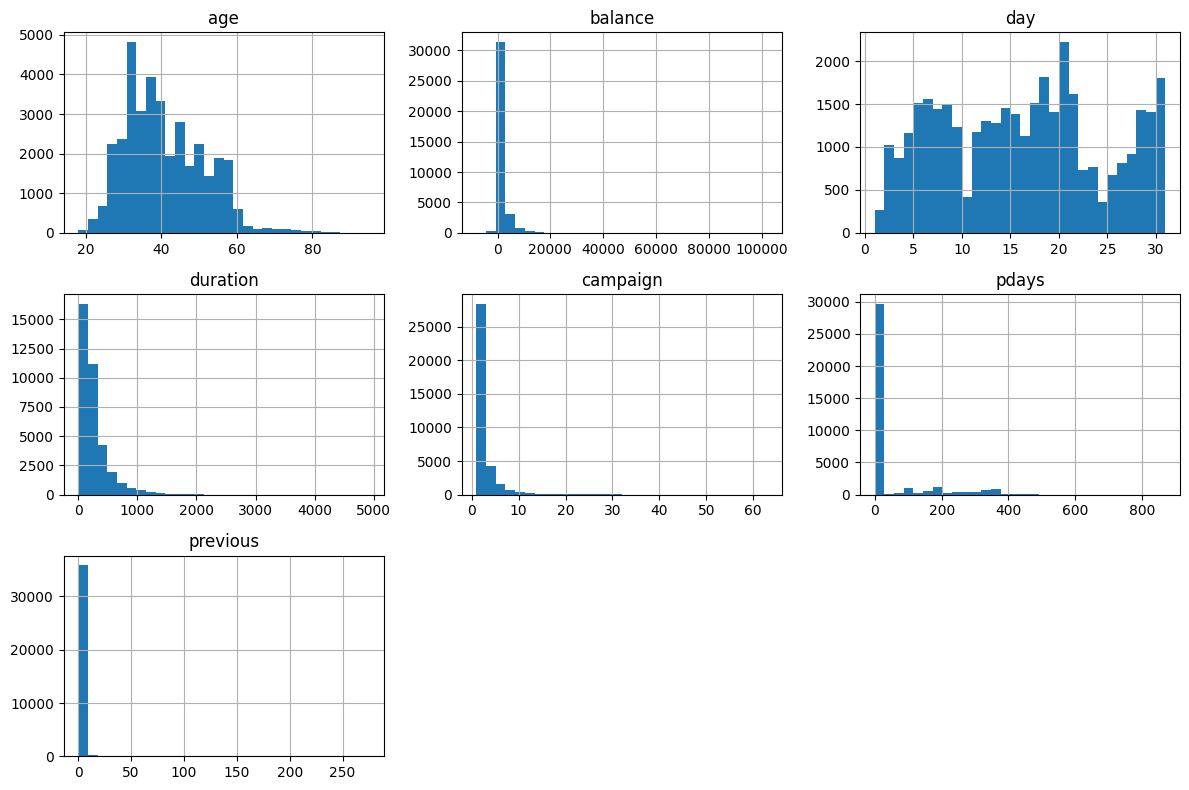

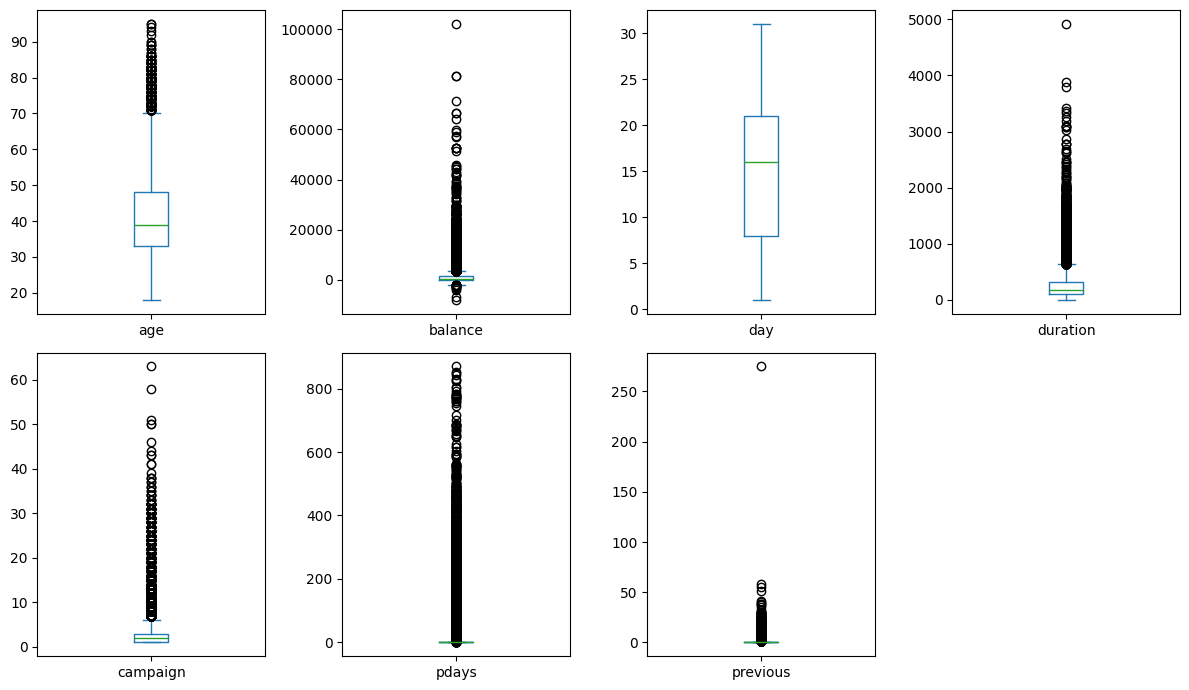

No previous contact (%): 81.79606281796062


In [16]:
display(df_eda[numerical_features].describe().T)
df_eda[numerical_features].hist(bins=30, figsize=(12, 8))
plt.tight_layout()
plt.show()

df_eda[numerical_features].plot.box(subplots=True, layout=(2, 4), figsize=(12, 7))
plt.tight_layout()
plt.show()
print("No previous contact (%):", 100 * df_eda["pdays"].eq(-1).mean())

Boxplots use the IQR rule to flag potential outliers, which are not necessarily errors. The special value `pdays = -1` means no previous contact and is not an outlier. A zero IQR, as for `previous`, limits the usefulness of the rule.

**Interpretation:** `balance`, `duration` and `campaign` have right-skewed distributions, and the numerical features have very different scales. Negative balances can be valid. About 82% of clients have `pdays = -1`, and the `previous` feature has a zero IQR because most clients have no previous contacts.

### 3.5. Categorical Features

We inspect the frequency of each category to identify dominant and rare groups.

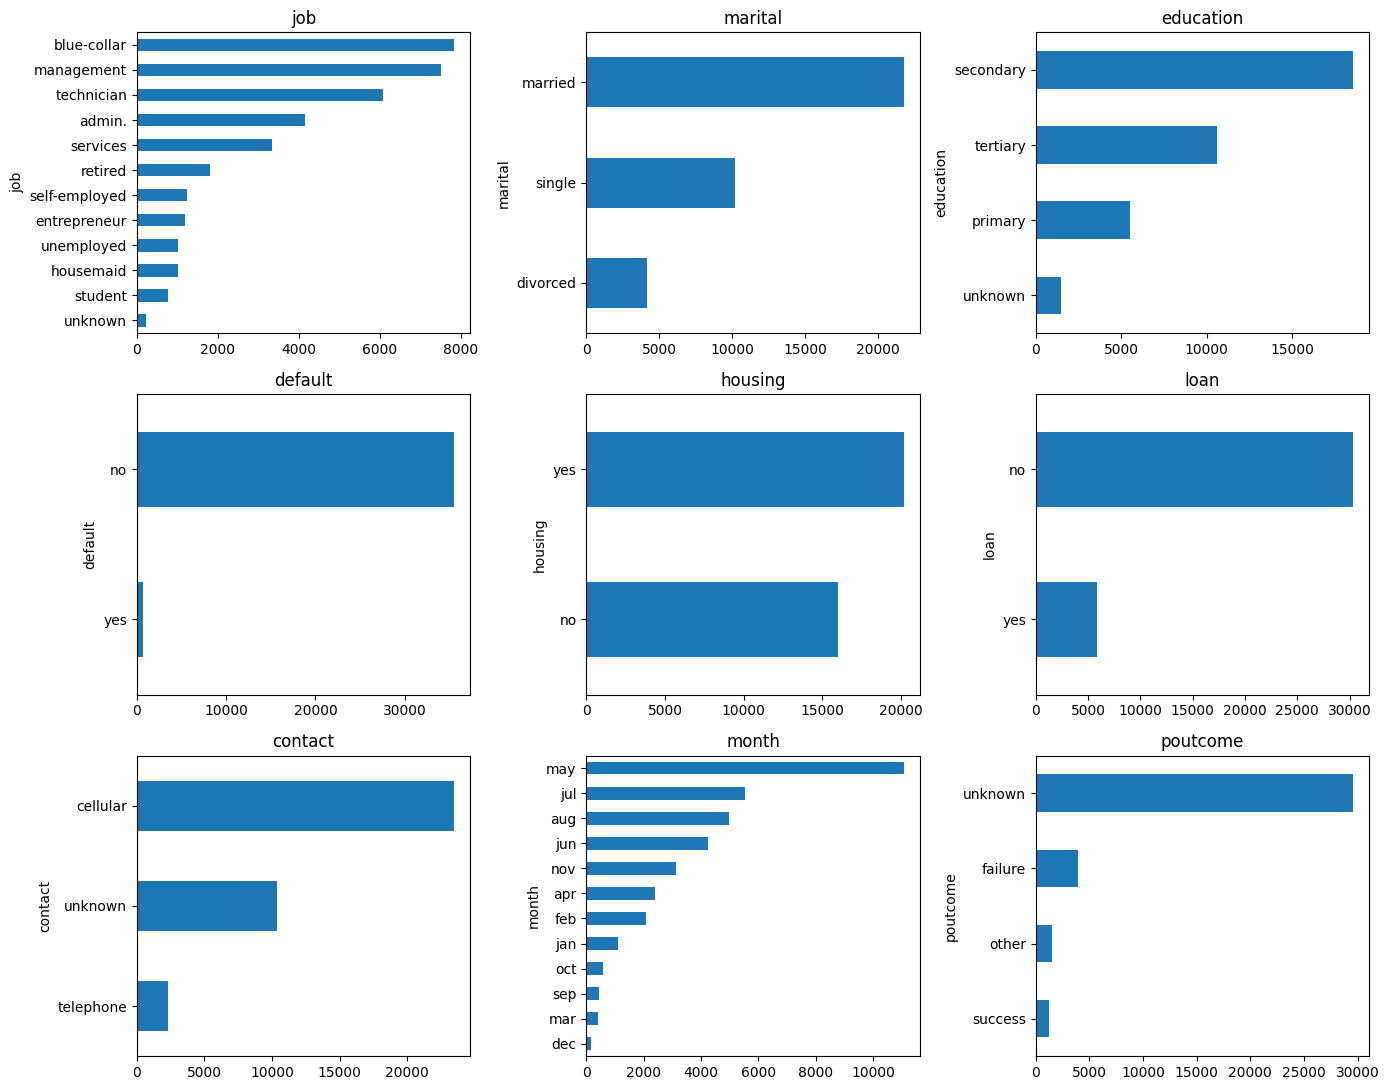

In [17]:
fig, axes = plt.subplots(3, 3, figsize=(14, 11))
for feature, ax in zip(categorical_features, axes.flat):
    df_eda[feature].value_counts().sort_values().plot.barh(ax=ax, title=feature)
plt.tight_layout()
plt.show()

**Interpretation:** The categories are not equally represented. For example, `blue-collar` is the most frequent job and `may` is the most frequent contact month. Rare categories may produce unstable estimates. We will start with one-hot encoding and keep the original categories unless later evidence supports grouping them.

### 3.6. Target Distribution

In the provided CSV, `y = 1` means no subscription and `y = 2` means subscription. We create a binary target only in the EDA copy to make subscription rates easier to calculate. This derived target must not be used as an input feature.

,Count,Percentage
No subscription,31937,88.301814
Subscription,4231,11.698186


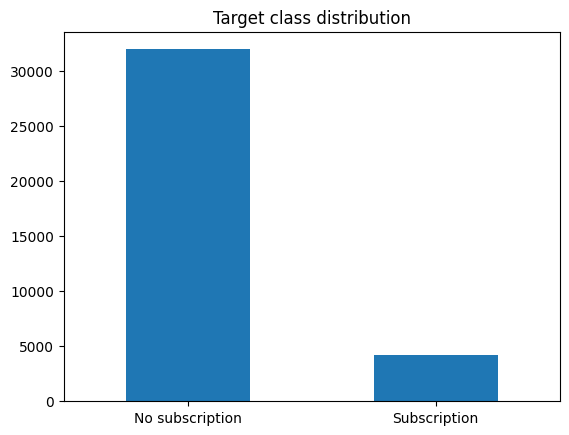

In [18]:
df_eda["subscribed"] = df_eda["y"].map({1: 0, 2: 1})
counts = df_eda["subscribed"].value_counts().sort_index()
counts.index = ["No subscription", "Subscription"]
display(pd.DataFrame({"Count": counts, "Percentage": 100 * counts / counts.sum()}))
counts.plot.bar(rot=0, title="Target class distribution")
plt.show()

**Interpretation:** Approximately 88.3% of the development observations belong to the negative class and 11.7% to the positive class. A classifier that always predicts no subscription would already obtain about 88% accuracy.

### 3.7. Feature Relationships and Correlations

We compare numerical medians by target class, study Pearson correlations and calculate subscription rates by category. These are exploratory associations, not causal effects.

subscribed,0,1
age,39.0,38.0
balance,419.0,740.0
day,16.0,15.0
duration,164.0,426.0
campaign,2.0,2.0
pdays,-1.0,-1.0
previous,0.0,0.0


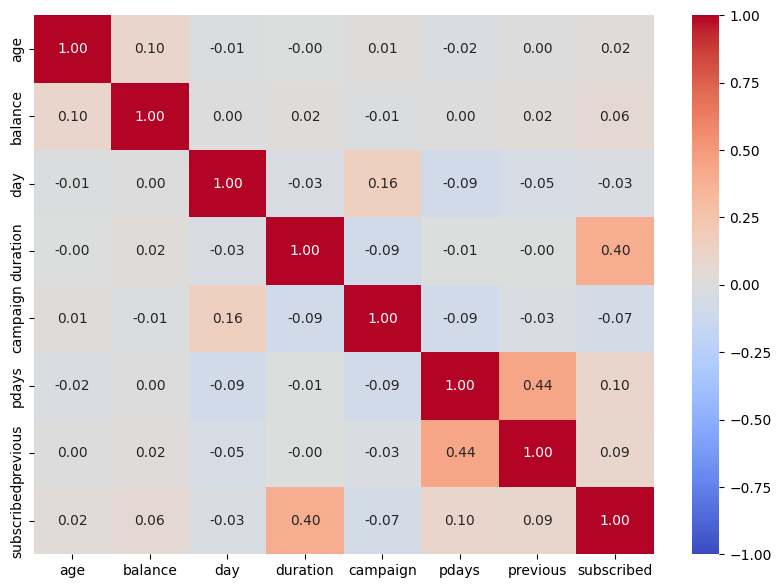

job (rate in %)


,count,rate
job,,
admin.,4141,12.29
blue-collar,7830,7.29
entrepreneur,1186,8.52
housemaid,1013,8.39
management,7511,13.86
retired,1812,22.96
self-employed,1243,11.42
services,3348,8.90
student,758,28.89


marital (rate in %)


,count,rate
marital,,
divorced,4170,12.25
married,21771,10.04
single,10227,15.01


education (rate in %)


,count,rate
education,,
primary,5531,8.62
secondary,18561,10.67
tertiary,10594,14.89
unknown,1482,13.23


... (8 outputs left out)

month (rate in %)


,count,rate
month,,
apr,2394,19.55
aug,4986,10.93
dec,178,47.19
feb,2078,16.79
jan,1119,10.19
jul,5537,9.26
jun,4237,10.41
mar,391,50.90
may,11062,6.68


poutcome (rate in %)


,count,rate
poutcome,,
failure,3889,12.29
other,1485,16.50
success,1205,64.65
unknown,29589,9.22


In [19]:
display(df_eda.groupby("subscribed")[numerical_features].median().T)
plt.figure(figsize=(10, 7))
sns.heatmap(df_eda[numerical_features + ["subscribed"]].corr(),
            annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.show()

for feature in categorical_features:
    rates = df_eda.groupby(feature)["subscribed"].agg(count="size", rate="mean")
    rates["rate"] *= 100
    print(feature, "(rate in %)")
    display(rates.round(2))

**Interpretation:** `previous` and `pdays` show a moderate positive correlation (0.44). Both describe previous marketing contacts, and clients who have never been contacted generally have `previous = 0` and `pdays = -1`. They measure different aspects of contact history, so we will initially keep both features.

`duration` has the strongest numerical correlation with subscription (about 0.40). However, the call duration is not known before the call, so we will exclude it from the predictive features for pre-call targeting. We must also ensure that other campaign-related variables are available at prediction time: in particular, `campaign` includes the last contact, and its final value may not be known before that contact. We will clarify its use during preprocessing.

A successful previous campaign (`poutcome = success`) is associated with a much higher subscription rate (about 65%). Some months also show higher rates but have relatively few observations. No pair of numerical features is strongly correlated. Weak or moderate Pearson correlations alone do not justify removing features, because nonlinear relationships and interactions may exist.

## 4. Unsupervised Exploration

We explore the development set without using the target to fit any unsupervised method. We use PCA for visualization, K-Means to identify groups and Isolation Forest to detect unusual observations. The test set remains untouched.

### 4.1. Data Preparation

K-Means and PCA are sensitive to feature scales. We standardize numerical features and one-hot encode categorical features. We keep `unknown` as a category and retain `pdays = -1` for now. We exclude `duration` and, conservatively, `campaign` because the final call duration and contact count may not be known before a call. We assume the planned contact channel and date are available. This exploratory transformation will not be reused as a fitted preprocessing step during supervised cross-validation.

In [20]:
X_unsup = df_train.drop(columns=["y", "duration", "campaign"])
num_cols = X_unsup.select_dtypes(include="number").columns
cat_cols = X_unsup.select_dtypes(exclude="number").columns

unsup_preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols)
])
X_unsup_prepared = unsup_preprocessor.fit_transform(X_unsup)
print("Prepared data shape:", X_unsup_prepared.shape)

Prepared data shape: (36168, 49)


### 4.2. Principal Component Analysis (PCA)

We project the prepared features onto two principal components to visualize the observations. The explained variance ratio measures how much of the original variability is retained.

In [28]:
pca = PCA(n_components=2)
projection = pd.DataFrame(pca.fit_transform(X_unsup_prepared),
                          columns=["PC1", "PC2"], index=df_train.index)
print("Explained variance (%):", (100 * pca.explained_variance_ratio_).round(1))
print("Total explained variance (%):", round(100 * pca.explained_variance_ratio_.sum(), 1))

Explained variance (%): [17.5 12.8]
Total explained variance (%): 30.2


**Interpretation:** The first two components explain about 30% of the variance (17.5% and 12.8%). A two-dimensional projection is useful for visualization but loses much of the information. We therefore fit K-Means on all prepared features rather than on the two PCA components. PCA is not used as a predictive feature transformation at this stage.

### 4.3. K-Means Clustering

We compare 2 to 6 clusters using the silhouette score (higher is better). We fit each model on the full development set and compute the score on a reproducible sample of 2,000 observations to limit computation time. The target is not involved in choosing the number of clusters.

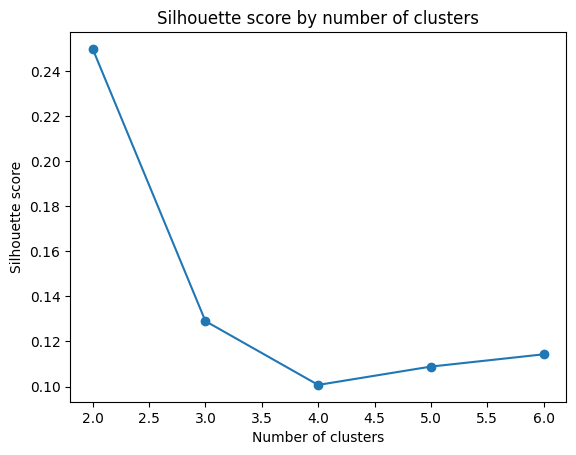

Selected k: 2 | Silhouette score: 0.25


In [22]:
scores = {}
for k in range(2, 7):
    labels = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X_unsup_prepared)
    scores[k] = silhouette_score(X_unsup_prepared, labels, sample_size=2000, random_state=42)

pd.Series(scores).plot(marker="o", title="Silhouette score by number of clusters")
plt.xlabel("Number of clusters")
plt.ylabel("Silhouette score")
plt.show()
best_k = max(scores, key=scores.get)
print("Selected k:", best_k, "| Silhouette score:", round(scores[best_k], 3))

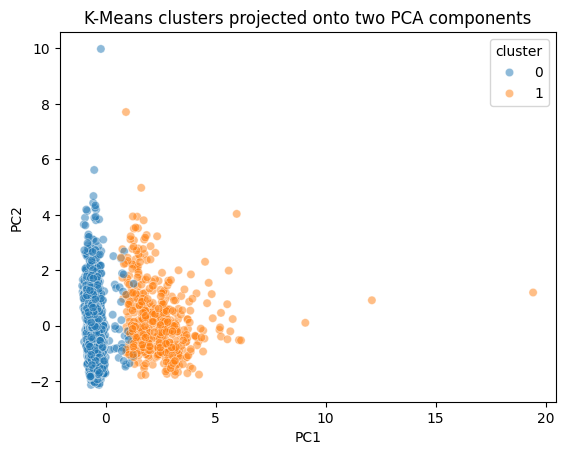

In [23]:
kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=42)
projection["cluster"] = kmeans.fit_predict(X_unsup_prepared)
sns.scatterplot(data=projection.sample(3000, random_state=42),
                x="PC1", y="PC2", hue="cluster", palette="tab10", alpha=0.5)
plt.title("K-Means clusters projected onto two PCA components")
plt.show()

**Interpretation:** For the supplied CSV, two clusters give the highest silhouette score among the tested values (about 0.25). This suggests some structure but not strongly separated groups. The PCA plot is only a partial representation of the space in which K-Means was fitted. Cluster numbers have no inherent meaning.

### 4.4. Cluster Profiles and Target Relationship

After clustering, we use the original features to describe each group. We compare subscription rates to determine whether the discovered groups are associated with the target. The target is used only for interpretation, not for fitting or selecting the clusters.

,count,age,balance,previous,pdays
cluster,,,,,
0,30075,39.0,421.0,0.0,-1.0
1,6093,38.0,598.0,2.0,213.0


,housing,contact,poutcome
cluster,,,
0,yes,cellular,unknown
1,yes,cellular,failure


,subscribed
cluster,
0,9.71
1,21.50


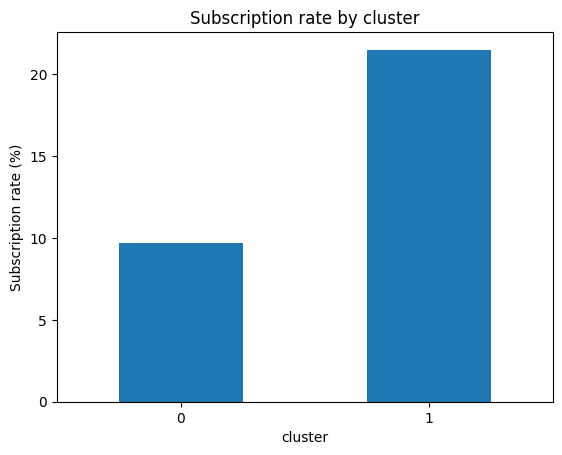

In [24]:
profiles = df_train.assign(cluster=projection["cluster"],
                           subscribed=df_train["y"].eq(2).astype(int))
display(profiles.groupby("cluster").agg(
    count=("age", "size"), age=("age", "median"), balance=("balance", "median"),
    previous=("previous", "median"), pdays=("pdays", "median")
))
display(profiles.groupby("cluster")[["housing", "contact", "poutcome"]].agg(
    lambda values: values.mode().iloc[0]
))
rates = 100 * profiles.groupby("cluster")["subscribed"].mean()
display(rates.round(2))
rates.plot.bar(rot=0, title="Subscription rate by cluster", ylabel="Subscription rate (%)")
plt.show()

**Interpretation:** The larger group contains about 83% of observations and has a median of zero previous contacts and `pdays = -1`. Its subscription rate is about 9.7%. The smaller group has a median of two previous contacts, `pdays = 213` and a higher subscription rate (about 21.5%). Contact history appears to be a major distinction between the groups. These associations do not demonstrate causality. Correlated contact-history features and the relative weighting of encoded variables can influence the clustering.

### 4.5. Anomaly Detection

Isolation Forest detects observations that are easier to isolate than the majority. We set the contamination parameter to 1% as an exploratory choice. We compare the flagged observations with the rest of the development set.

In [25]:
isolation_forest = IsolationForest(contamination=0.01, random_state=42)
profiles["anomaly"] = isolation_forest.fit_predict(X_unsup_prepared) == -1
print("Flagged observations:", profiles["anomaly"].sum())
display(profiles.groupby("anomaly")[["age", "balance", "pdays", "previous"]].median())
display((100 * profiles.groupby("anomaly")["subscribed"].mean()).round(2))

Flagged observations: 362


,age,balance,pdays,previous
anomaly,,,,
False,39.0,451.0,-1.0,0.0
True,48.0,478.5,178.0,2.0


,subscribed
anomaly,
False,11.57
True,24.31


**Interpretation:** About 362 observations are flagged by design. In the supplied data, flagged clients tend to be older (median age 48 versus 39) and to have more previous contacts (median 2 versus 0). Their subscription rate is also higher (about 24% versus 12%). These observations may represent valid and informative customer profiles, so we will not remove them automatically.

### 4.6. Conclusions

The unsupervised exploration reveals several interesting characteristics of the dataset:

- The first two principal components explain only 30.2% of the total variance. PCA is therefore used for visualization rather than dimensionality reduction at this stage.
- K-Means identifies two groups with different contact histories and subscription rates. However, the silhouette score of 0.25 indicates limited cluster separation.
- Previous marketing contacts appear to be an important source of information for predicting subscriptions.
- Isolation Forest identifies unusual observations that may represent valid customer profiles rather than data errors.

Based on these results, we will retain all observations and will not use PCA or cluster labels as predictive features at this stage.

The original features will be retained, subject to the prediction-time availability constraints discussed earlier.

During preprocessing, we will consider creating a new feature indicating whether a client has previously been contacted.